# 1.Setup


In [2]:
from dotenv import load_dotenv
import os
load_dotenv()


True

In [7]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-20b")

In [9]:
response = llm.invoke("hello")
response

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We have a conversation: user says "hello". We need to respond politely. The system says: "You are ChatGPT". There\'s no other instruction. Just respond.'}, response_metadata={'token_usage': {'completion_tokens': 53, 'prompt_tokens': 72, 'total_tokens': 125, 'completion_time': 0.054977621, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.003374092, 'prompt_tokens_details': None, 'queue_time': 0.304346622, 'total_time': 0.058351713}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_84bb35977d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1b58f-0f2c-7550-8856-86e9ffb4e882-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 53, 'total_tokens': 125, 'output_token_details': {'reasoning': 35}})

# 2. State - Global State to pass the data between all the nodes 

In [10]:
from pydantic import BaseModel

class UserState(BaseModel):
    name: str = ""
    email: str = ""
    age:  int = 0
    
state = UserState(name="Bruce")

In [11]:
state

UserState(name='Bruce', email='', age=0)

## Step 2.1 - Building the Graph using the langgraph

In [15]:
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel

class MyState(BaseModel):
    messages: str = ""
    
def greet(state:MyState):
    """I am a greet node..."""
    print(state.messages)
    return state

graph = StateGraph(MyState)
graph.add_node("xyz_node", greet)

graph.add_edge(START, "xyz_node")
graph.add_edge("xyz_node", END)

final_graph = graph.compile()


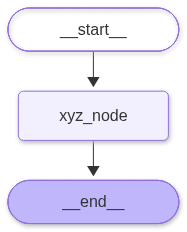

In [ ]:
final_graph